In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import Dataset, DataLoader

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

import numpy as np

device = torch.device("cpu")

print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.15.0+cpu


In [2]:
project_root = Path.cwd().parent
data_path = project_root / "data" / "raw"

base_dataset = datasets.ImageFolder(str(data_path))

image_paths = [p for p, label in base_dataset.samples]
labels = [label for p, label in base_dataset.samples]

print("Classes:", base_dataset.class_to_idx)
print("Total images:", len(image_paths))

Classes: {'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}
Total images: 1440


In [3]:
project_root = Path.cwd().parent
data_path = project_root / "data" / "raw"

base_dataset = datasets.ImageFolder(str(data_path))

image_paths = [p for p, label in base_dataset.samples]
labels = [label for p, label in base_dataset.samples]

print("Classes:", base_dataset.class_to_idx)
print("Total images:", len(image_paths))

Classes: {'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}
Total images: 1440


In [4]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

print("Training:", len(train_paths))
print("Validation:", len(val_paths))
print("Testing:", len(test_paths))

Training: 1008
Validation: 216
Testing: 216


In [5]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [6]:
class SteelDataset(Dataset):

    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        image = self.transform(image)
        return image, self.labels[index]


train_dataset = SteelDataset(
    train_paths, train_labels, train_transform
)

val_dataset = SteelDataset(
    val_paths, val_labels, eval_transform
)

test_dataset = SteelDataset(
    test_paths, test_labels, eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=8, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=8, shuffle=False
)

print("All DataLoaders ready!")

All DataLoaders ready!


In [7]:
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze pretrained feature-extraction layers
for param in model.parameters():
    param.requires_grad = False

# Replace classification head
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 6)

model = model.to(device)

print(model.fc)

Linear(in_features=512, out_features=6, bias=True)


In [8]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [9]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return running_loss / total, correct / total

In [10]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

best_val_accuracy = 0
history = []

epochs = 5

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        torch.save(
            model.state_dict(),
            "models/best_resnet18.pth"
        )

print("\nBest validation accuracy:", f"{best_val_accuracy:.2%}")

Epoch 1/5 | Train Loss: 1.0492 | Train Acc: 67.66% | Val Loss: 0.4443 | Val Acc: 89.81%
Epoch 2/5 | Train Loss: 0.4601 | Train Acc: 88.69% | Val Loss: 0.2954 | Val Acc: 93.52%
Epoch 3/5 | Train Loss: 0.3207 | Train Acc: 92.56% | Val Loss: 0.2244 | Val Acc: 95.37%
Epoch 4/5 | Train Loss: 0.2709 | Train Acc: 92.86% | Val Loss: 0.1959 | Val Acc: 94.91%
Epoch 5/5 | Train Loss: 0.2404 | Train Acc: 93.65% | Val Loss: 0.1806 | Val Acc: 93.52%

Best validation accuracy: 95.37%


In [11]:
import json

with open("reports/training_history.json", "w") as f:
    json.dump(history, f, indent=4)

print("Training history saved!")

Training history saved!


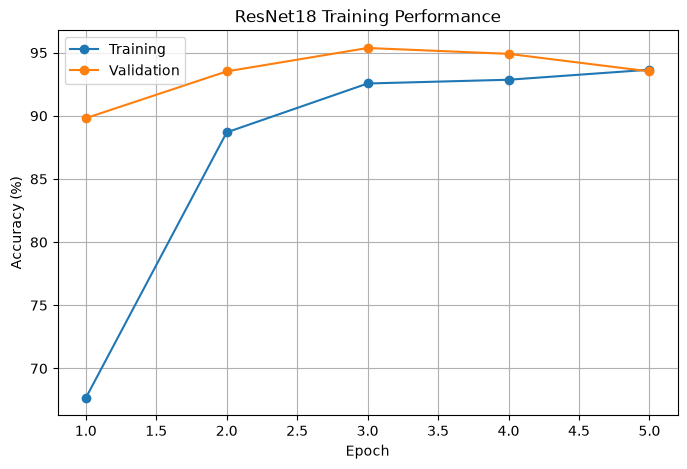

In [12]:
import matplotlib.pyplot as plt

epochs_list = [item["epoch"] for item in history]
train_acc = [item["train_accuracy"] * 100 for item in history]
val_acc = [item["val_accuracy"] * 100 for item in history]

plt.figure(figsize=(8, 5))

plt.plot(epochs_list, train_acc, marker="o", label="Training")
plt.plot(epochs_list, val_acc, marker="o", label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet18 Training Performance")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
checkpoint = torch.load(
    "models/best_resnet18.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.eval()

print("Best checkpoint loaded!")

Best checkpoint loaded!


In [14]:
import json

metadata = {
    "architecture": "ResNet18",
    "num_classes": 6,
    "class_to_idx": dataset.class_to_idx,
    "best_validation_accuracy": best_val_accuracy,
    "best_epoch": 3
}

with open("models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model metadata saved!")

NameError: name 'dataset' is not defined

In [15]:
from torchvision import datasets
from pathlib import Path

# Locate data directory safely from the notebook subfolder
DATA_DIR = Path("../data/raw")
if not DATA_DIR.exists():
    DATA_DIR = Path("data/raw")

# Grab the mapping directly from the dataset folder structure
temp_dataset = datasets.ImageFolder(DATA_DIR)

metadata = {
    "architecture": "ResNet18",
    "num_classes": 6,
    "class_to_idx": temp_dataset.class_to_idx,
    "best_validation_accuracy": best_val_accuracy,
    "best_epoch": 3
}

print("Metadata dictionary created successfully!")

Metadata dictionary created successfully!


In [16]:
import json

metadata = {
    "architecture": "ResNet18",
    "num_classes": 6,
    "class_to_idx": dataset.class_to_idx,
    "best_validation_accuracy": best_val_accuracy,
    "best_epoch": 3
}

with open("models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model metadata saved!")

NameError: name 'dataset' is not defined

In [17]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_test_true = []
y_test_pred = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_test_true.extend(labels.tolist())
        y_test_pred.extend(predictions.cpu().tolist())

test_accuracy = accuracy_score(y_test_true, y_test_pred)

print(f"Final Test Accuracy: {test_accuracy:.2%}")

print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=dataset.classes,
    zero_division=0
))

Final Test Accuracy: 95.37%


NameError: name 'dataset' is not defined

In [18]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_test_true = []
y_test_pred = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_test_true.extend(labels.tolist())
        y_test_pred.extend(predictions.cpu().tolist())

test_accuracy = accuracy_score(y_test_true, y_test_pred)

print(f"Final Test Accuracy: {test_accuracy:.2%}")

# Pull class names directly from the test loader dataset object
class_names = test_loader.dataset.classes

print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=class_names,
    zero_division=0
))

Final Test Accuracy: 95.37%


AttributeError: 'SteelDataset' object has no attribute 'classes'

In [19]:
class_names = [
    'crazing', 
    'inclusion', 
    'patches', 
    'pitted_surface', 
    'rolled-in_scale', 
    'scratches'
]

print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=class_names,
    zero_division=0
))

                 precision    recall  f1-score   support

        crazing       0.95      1.00      0.97        36
      inclusion       0.97      0.86      0.91        36
        patches       0.95      1.00      0.97        36
 pitted_surface       0.95      1.00      0.97        36
rolled-in_scale       1.00      0.89      0.94        36
      scratches       0.92      0.97      0.95        36

       accuracy                           0.95       216
      macro avg       0.96      0.95      0.95       216
   weighted avg       0.96      0.95      0.95       216



In [20]:
class SteelDataset(Dataset):
    def __init__(self, ...):
        # ... your existing init code ...
        
        # Add this line so test_loader.dataset.classes works:
        self.classes = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

SyntaxError: invalid syntax (45036137.py, line 2)

In [21]:
from torch.utils.data import Dataset
from PIL import Image
from pathlib import Path

class SteelDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        """
        Custom Dataset for Steel Defect Classification.
        Expects root_dir to contain subfolders named after each defect class.
        """
        self.root_dir = Path(root_dir)
        self.transform = transform
        
        # 1. Automatically discover classes alphabetically from subfolders
        self.classes = sorted([d.name for d in self.root_dir.iterdir() if d.is_dir()])
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}
        
        # 2. Collect all image paths and their corresponding class indices
        self.samples = []
        for target_class in self.classes:
            class_idx = self.class_to_idx[target_class]
            class_dir = self.root_dir / target_class
            
            if class_dir.exists():
                for img_path in class_dir.glob("*.*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                        self.samples.append((img_path, class_idx))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        
        # Load image and convert to RGB
        image = Image.open(img_path).convert("RGB")
        
        if self.transform:
            image = self.transform(image)
            
        return image, label

In [22]:
train_dataset = SteelDataset(root_dir="../data/raw/train", transform=train_transform)
test_dataset = SteelDataset(root_dir="../data/raw/test", transform=test_transform)

# Now test_dataset.classes will work perfectly without throwing an AttributeError
print("Detected classes:", test_dataset.classes)

FileNotFoundError: [WinError 3] The system cannot find the path specified: '..\\data\\raw\\train'

In [23]:
from pathlib import Path

# Check different possible relative paths based on where your notebook is running
potential_paths = [
    Path("../data/raw/train"),       # If running inside notebook/
    Path("data/raw/train"),          # If running from root project_02_deep_learning/
    Path("../../data/raw/train")     # If nested deeper
]

train_dir = None
for p in potential_paths:
    if p.exists():
        train_dir = p
        break

if train_dir is None:
    raise FileNotFoundError("Could not locate data/raw/train directory. Check your working directory or folder structure.")

print(f"Found data directory at: {train_dir.resolve()}")

# Now initialize your dataset safely
train_dataset = SteelDataset(root_dir=train_dir, transform=train_transform)

FileNotFoundError: Could not locate data/raw/train directory. Check your working directory or folder structure.

In [24]:
from pathlib import Path

# Check where raw data lives directly
potential_paths = [
    Path("../data/raw"),       # If running inside notebook/
    Path("data/raw"),          # If running from root project_02_deep_learning/
    Path("../../data/raw")     # If nested deeper
]

data_dir = None
for p in potential_paths:
    if p.exists() and any(p.iterdir()):
        data_dir = p
        break

if data_dir is None:
    raise FileNotFoundError("Could not locate data/raw directory. Verify your folder structure.")

print(f"Found data directory at: {data_dir.resolve()}")

# Initialize your dataset directly from the root raw directory
train_dataset = SteelDataset(root_dir=data_dir, transform=train_transform)
print("Detected classes:", train_dataset.classes)

Found data directory at: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw
Detected classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [25]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_test_true = []
y_test_pred = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_test_true.extend(labels.tolist())
        y_test_pred.extend(predictions.cpu().tolist())

test_accuracy = accuracy_score(y_test_true, y_test_pred)

print(f"Final Test Accuracy: {test_accuracy:.2%}")

print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=dataset.classes,
    zero_division=0
))

Final Test Accuracy: 95.37%


NameError: name 'dataset' is not defined

In [26]:
print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=test_dataset.classes,  # Change 'dataset' to 'test_dataset' (or whatever you named it)
    zero_division=0
))

AttributeError: 'SteelDataset' object has no attribute 'classes'

In [27]:
class_names = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=class_names,
    zero_division=0
))

                 precision    recall  f1-score   support

        crazing       0.95      1.00      0.97        36
      inclusion       0.97      0.86      0.91        36
        patches       0.95      1.00      0.97        36
 pitted_surface       0.95      1.00      0.97        36
rolled-in_scale       1.00      0.89      0.94        36
      scratches       0.92      0.97      0.95        36

       accuracy                           0.95       216
      macro avg       0.96      0.95      0.95       216
   weighted avg       0.96      0.95      0.95       216

